# 07 · Backtest framework v2

用 A（carry）演示新的回测框架：**持仓按合约记账、成本分三层扣、所有诊断都是时序的**。

- 时序：t 日 settle 出信号 → t+1 日 settle 成交 → 从 t+2 开始吃收益。
- 成本：half-spread（一阶）→ 交易所和经纪商 fee → square-root market impact，逐层报告。
- 资本：\$10m 是**整个组合**的资本，不是每个商品各 \$10m；收益 = P&L / capital，不复利。资本只影响 impact 这一层。
- 样本：1986–2015 train；2016–2026 test。

所有逻辑在 `src/`，notebook 只负责调用和叙述：

| 层 | 模块 | 做什么 |
|---|---|---|
| Marks | `src/marks.py` | 合约级 settle、跨缺失日不丢的价格变化、能否成交、滞后的 ADV 和波动率 |
| Sizing | `src/sizing.py` | signal → 腿级目标：等权 / inverse-vol / 流动性加权，k 天平滑，流动性 flag |
| Simulation | `src/simulate.py` | 持有合约数；到期、成交被 block、强制平仓 |
| Costs | `src/costs.py` | half-spread、fee、impact 三层，文献依据见 `docs/transaction_costs.md` |
| Diagnostics | `src/horizon.py` | 固定 pair 的多 horizon 前瞻收益、时序 IC、block bootstrap、自身历史分位数分组 |
| Report / Figures | `src/report.py`, `src/figures.py` | 表格；期刊格式的图，存到 `output/figures/` |

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [2]:
import pandas as pd
from IPython.display import display

from src import horizon, marks, panel, report, signals, simulate, sizing, specs
from src import figures as F
from src import plotstyle as ps

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("LaTeX text rendering:", ps.use())
STRATEGY = "Carry (idea A)"

LaTeX text rendering: True


## 1. 数据：pairs、marks、流动性 flag

Pair = 最近两个 eligible 的相邻合约，`k=5`（交割月开始前至少 5 个 session 退出）+ `d=5`（最后交易日前至少 5 个 session 换月）。
最后交易日在交易所日历上提前公开，所以 `d` 是 ex ante 的；不加 `d`，CL/CO/NG 的近月腿会拿到到期。

流动性 flag：较薄那条腿的滞后 20 日 ADV ≥ 100 张。**不达标的日子是显式平仓**，不是"没信号继续拿着"。

In [3]:
rank = pd.read_parquet("data/processed/rank.parquet")
bt = panel.build_backtest_panel(rank, d=5, k=5)
mk = marks.build_marks(bt["contract"], specs.load_contract_specs())

pairs = sizing.filter_liquid(sizing.attach_leg_liquidity(bt["spread"], mk), min_adv=100)
print(f"pair-dates: {len(pairs):,}; liquid (thinner-leg ADV >= 100): {pairs['liquid'].mean():.1%}")
print(f"contract marks: {len(mk):,} rows")

pair-dates: 236,321; liquid (thinner-leg ADV >= 100): 86.1%
contract marks: 950,626 rows


## 2. Signal 和腿级目标

`target = sign(P_near − P_far)`：backwardation 做多 spread，contango 做空。

每个有信号的商品分到 gross notional 的 1/N（N 取过去 5 天的最大值，避免 ICE 在美国假日单独开市时把整个 book 压到一两个品种上）；
两条腿等名义，和 Paschke et al. (2020)、Bianchi et al. (2023) 一致。下面打印 CL 某一天的两条腿。

In [4]:
sig = signals.carry_signal(pairs)
legs = sizing.legs_from_signal(sig, pairs, scheme="equal", leg_ratio="notional")
display(legs.loc[(legs["root"] == "CL") & (legs["date"] == "2021-10-01")])

,date,root,group_id,contract,units,budget,target
382583,2021-10-01,CL,CL_CLX21_CLZ21,CLX21,1.000000,0.047619,1.0
382584,2021-10-01,CL,CL_CLX21_CLZ21,CLZ21,-1.003969,0.047619,1.0


## 3. 回测和分层绩效

\$10m、允许小数张合约；pair 或 target 不变就一直拿着合约，budget 漂移超过 25% 才 resize。

表格按 full / train / test 报四层：gross → 扣 half-spread → 再扣 fee → 再扣 impact。`turnover_x` = 每年成交名义 / 资本。
下面的图是四层的累计收益，灰底是 test 期。

In [5]:
cfg = simulate.SimConfig(capital=1e7, resize="on_change")
res = simulate.simulate(legs, mk, cfg)

perf = pd.concat({
    "full": report.performance_table(res),
    "train 1986-2015": report.performance_table(res, end="2015-12-31"),
    "test 2016-2026": report.performance_table(res, start="2016-01-01"),
}, names=["period"])
display(perf)
print(res.trades["reason"].value_counts().to_string())

layer  ann_ret_pct  ann_vol_pct  sharpe    t_nw  max_dd_pct  turnover_x  cost_bps_yr
period                                                                                                          
full            0           gross       -0.484        0.957  -0.506  -3.456     -24.239      26.148        0.000
                1   - half-spread       -0.843        0.958  -0.880  -5.988     -38.224      26.148       35.893
                2          - fees       -1.002        0.959  -1.045  -7.098     -44.462      26.148       51.836
                3  - impact (all)       -2.612        1.006  -2.596 -16.528    -109.099      26.148      212.761
train 1986-2015 0           gross       -0.561        0.995  -0.563  -3.437     -18.063      26.664        0.000
                1   - half-spread       -0.974        0.996  -0.978  -5.942     -30.556      26.664       41.365
                2          - fees       -1.155        0.998  -1.158  -7.020     -36.022      26.664       59.444
                3  - impact (all)       -3.026        1.054  -2.872 -16.106     -92.712      26.664      246.559
test 2016-2026  0           gross       -0.272        0.843  -0.323  -0.997      -6.220      24.718        0.000
                1   - half-spread       -0.480        0.843  -0.569  -1.752      -7.646      24.718       20.742
                2          - fees       -0.580        0.844  -0.688  -2.115      -8.419      24.718       30.767
                3  - impact (all)       -1.464        0.856  -1.710  -5.172     -16.361      24.718      119.166

reason
rebalance    32155
expiry           4


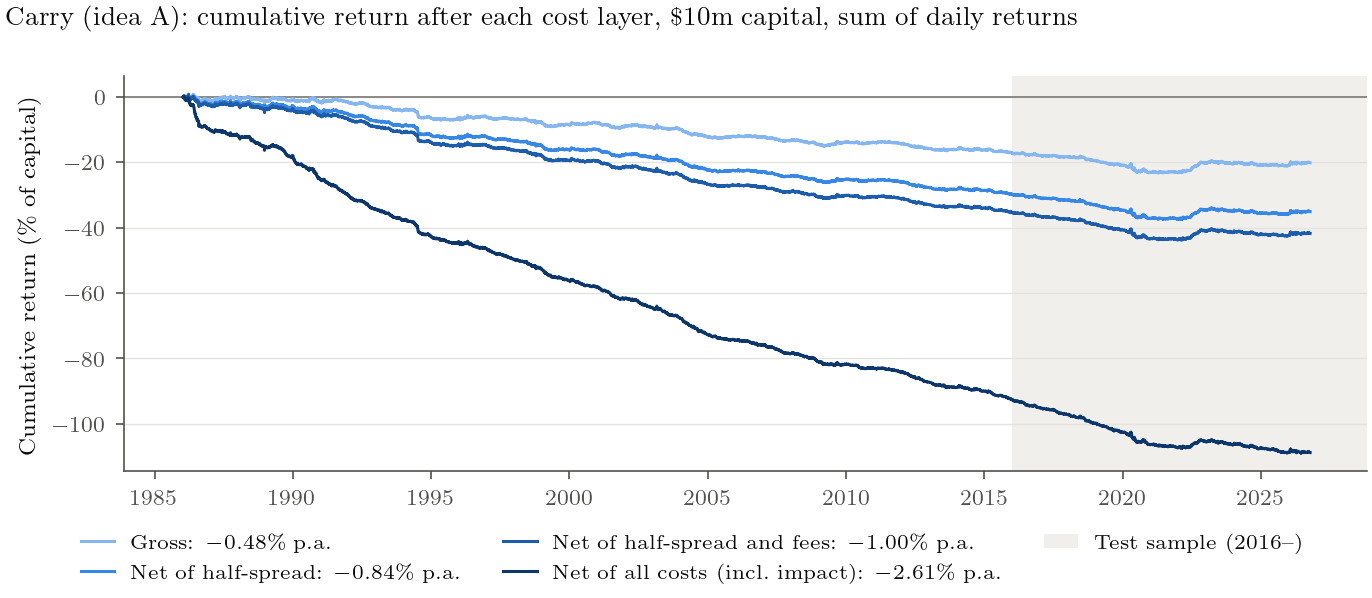

In [6]:
fig = F.nav_by_cost_layer(res, STRATEGY)
ps.save(fig, "carry_nav_by_cost_layer");

## 4. 换手和分商品成本

- 组合换手 = 成交名义 / 资本，年化；图 (a) 是 63 日滚动均值。
- 分商品换手 = 成交名义 / 该商品平均持仓名义，即**这个商品的 book 一年被换几遍**。单是月度 roll 就有约 24 遍。

第二张图按商品拆开 gross P&L 和三种成本（% of total capital / 年），黑点是 net；最后的表是同样的数字。

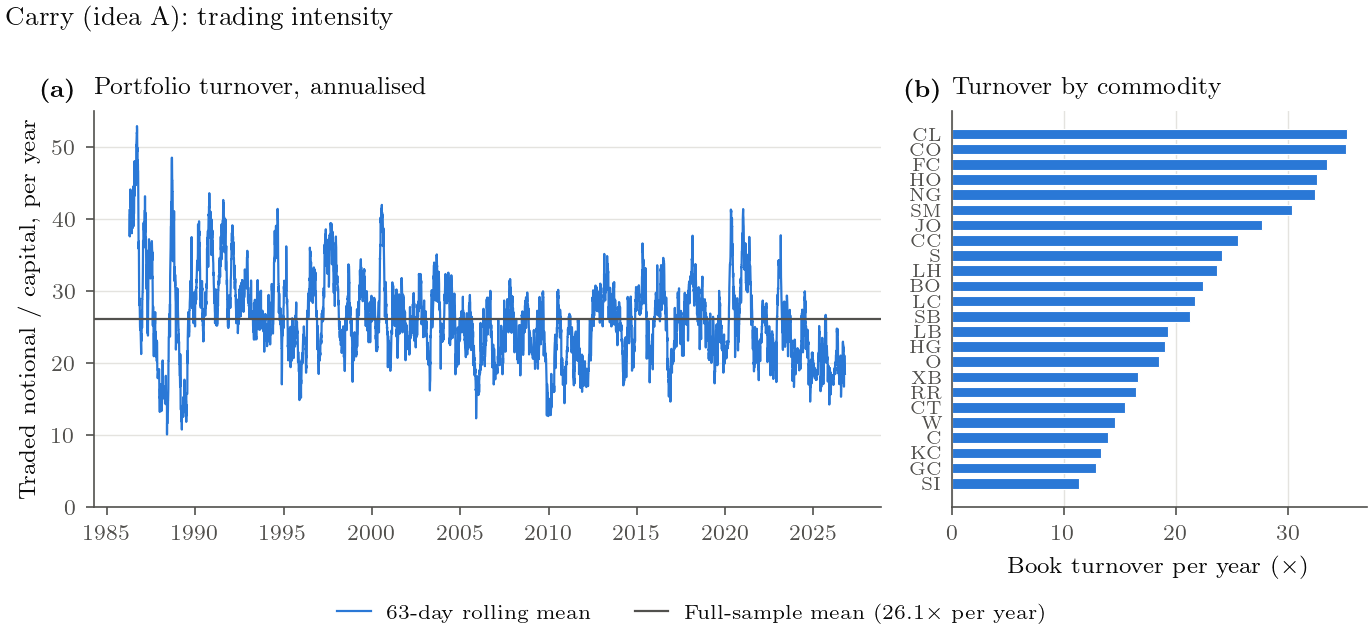

In [7]:
fig = F.turnover(res, STRATEGY)
ps.save(fig, "carry_turnover");

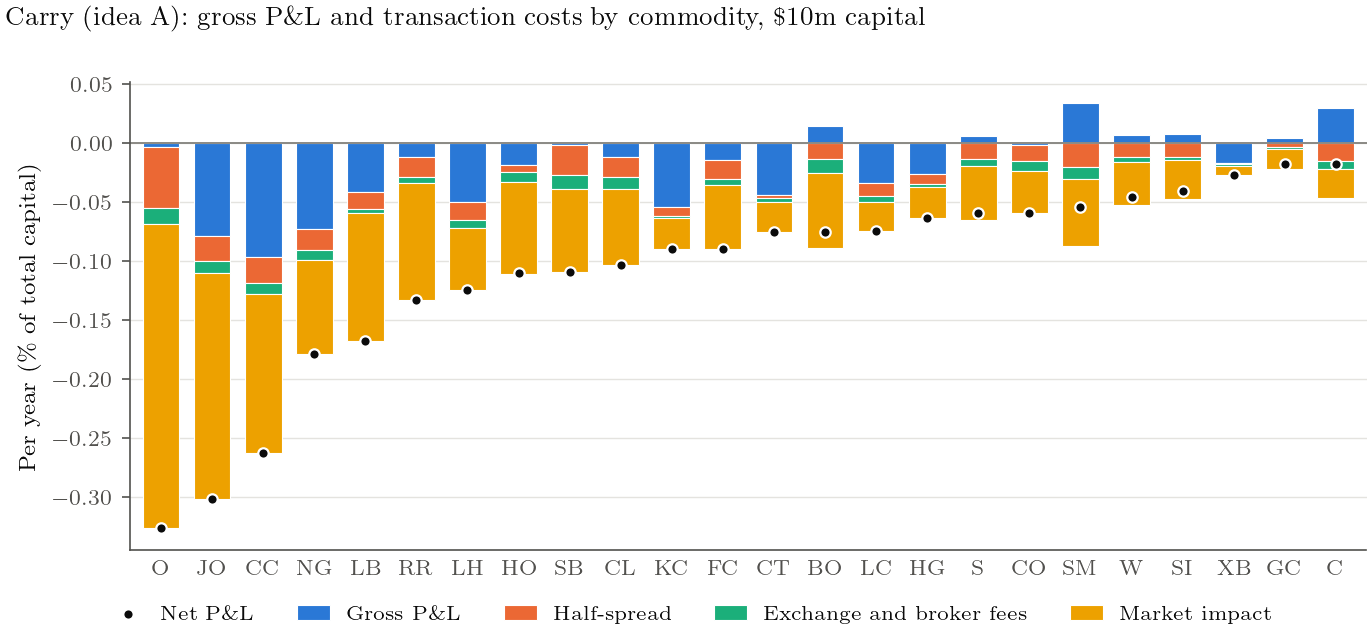

In [8]:
fig = F.commodity_pnl_and_costs(res, STRATEGY)
ps.save(fig, "carry_pnl_and_costs_by_commodity");

In [9]:
display(report.root_table(res))

,gross_pct_yr,half_spread_pct_yr,fee_pct_yr,impact_pct_yr,turnover_x,median_participation,impact_bps_of_book,net_pct_yr
root,,,,,,,,
O,-0.0038,0.0516,0.0131,0.2579,18.4266,0.0631,557.4641,-0.3264
JO,-0.0794,0.0208,0.0101,0.1914,27.6811,0.0215,431.8195,-0.3017
CC,-0.0968,0.0219,0.0094,0.1343,25.5522,0.0018,297.8412,-0.2624
NG,-0.0735,0.0176,0.0084,0.0796,32.3852,0.0003,172.7322,-0.1791
LB,-0.0416,0.0142,0.0041,0.1078,19.3133,0.0245,240.0477,-0.1676
RR,-0.0119,0.0171,0.0053,0.0985,16.4345,0.0422,234.2502,-0.1328
LH,-0.0501,0.0150,0.0071,0.0526,23.6084,0.0021,106.5513,-0.1248
HO,-0.0188,0.0065,0.0084,0.0771,32.5462,0.0004,135.8929,-0.1107
SB,-0.0024,0.0254,0.0118,0.0701,21.2292,0.0016,149.2389,-0.1097


## 5. 信号诊断（不经过成交和成本）

固定 t 日选出的 pair，算 settle(t+a) → settle(t+b) 的 `r_near − r_far`，再乘以信号方向，跨商品等权平均。
`[t+1, t+2]` 是 t+1 成交后的第一天；`[t+11, t+21]` 检验信号延迟 10 天后还有没有用。t 值用 Newey–West（lag = 窗口长度）。

图 (a) 是整个窗口的收益，(b) 除以窗口长度，看 edge 是衰减还是累积。

In [10]:
fwd = horizon.forward_returns(pairs, mk, horizons=horizon.DEFAULT_HORIZONS)
profile = horizon.horizon_profile(fwd, sig, score_col="target")
display(profile.round(3))

,horizon,days,mean_bps,bps_per_day,t_nw,hit_rate,n_dates
0,t+1->t+2,1,-0.511,-0.511,-4.634,0.487,10492
1,t+1->t+3,2,-0.909,-0.455,-4.789,0.501,10492
2,t+1->t+4,3,-1.204,-0.401,-4.502,0.503,10492
3,t+1->t+6,5,-1.699,-0.340,-3.818,0.500,10492
4,t+1->t+11,10,-4.219,-0.422,-5.072,0.493,10414
5,t+1->t+21,20,-8.428,-0.421,-5.247,0.478,10300
6,t+11->t+21,10,-3.922,-0.392,-3.835,0.474,10300


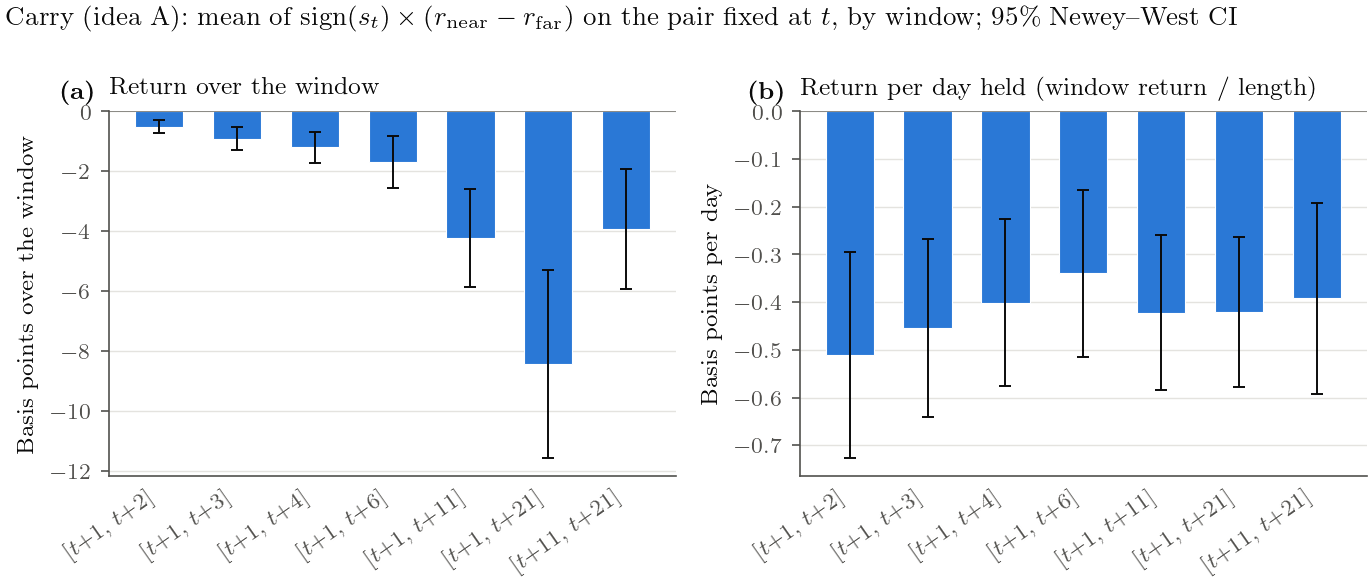

In [11]:
fig = F.horizon_profile(profile, STRATEGY)
ps.save(fig, "carry_horizon_profile");

### 收益随 horizon 怎么变（逐日边际 vs 累计）

上面的窗口是重叠的，看不出 edge 在哪一天。这里拆成两种：

- **逐日边际**：`[t+h, t+h+1]`，h = 1…20，即信号后第 h 天那一天的 signed return——看信号在哪一天衰减到 0。
- **累计**：`[t+1, t+1+h]`，即 t+1 成交、持有 h 天的总收益。

都是 gross、不经过成交，误差棒/带是 95% NW CI。

In [12]:
fwd_marg = horizon.forward_returns(pairs, mk, horizons=horizon.marginal_horizons(20))
fwd_cum = horizon.forward_returns(pairs, mk, horizons=horizon.cumulative_horizons(20))
marg = horizon.horizon_profile(fwd_marg, sig, score_col="target")
cum = horizon.horizon_profile(fwd_cum, sig, score_col="target")
display(marg[["horizon", "mean_bps", "t_nw", "hit_rate"]].round(3).T)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
horizon,t+1->t+2,t+2->t+3,t+3->t+4,t+4->t+5,t+5->t+6,t+6->t+7,t+7->t+8,t+8->t+9,t+9->t+10,t+10->t+11,t+11->t+12,t+12->t+13,t+13->t+14,t+14->t+15,t+15->t+16,t+16->t+17,t+17->t+18,t+18->t+19,t+19->t+20,t+20->t+21
mean_bps,-0.511,-0.399,-0.308,-0.268,-0.155,-0.249,-0.224,-0.186,-0.206,-0.257,-0.246,-0.265,-0.262,-0.174,-0.096,-0.022,-0.03,-0.076,-0.099,-0.237
t_nw,-4.634,-3.534,-2.629,-1.571,-0.89,-1.417,-1.227,-1.059,-1.158,-1.438,-1.356,-1.419,-1.404,-0.917,-0.496,-0.11,-0.151,-0.356,-0.446,-1.055
hit_rate,0.487,0.488,0.487,0.486,0.485,0.483,0.483,0.482,0.48,0.48,0.479,0.478,0.477,0.476,0.476,0.475,0.475,0.473,0.473,0.471


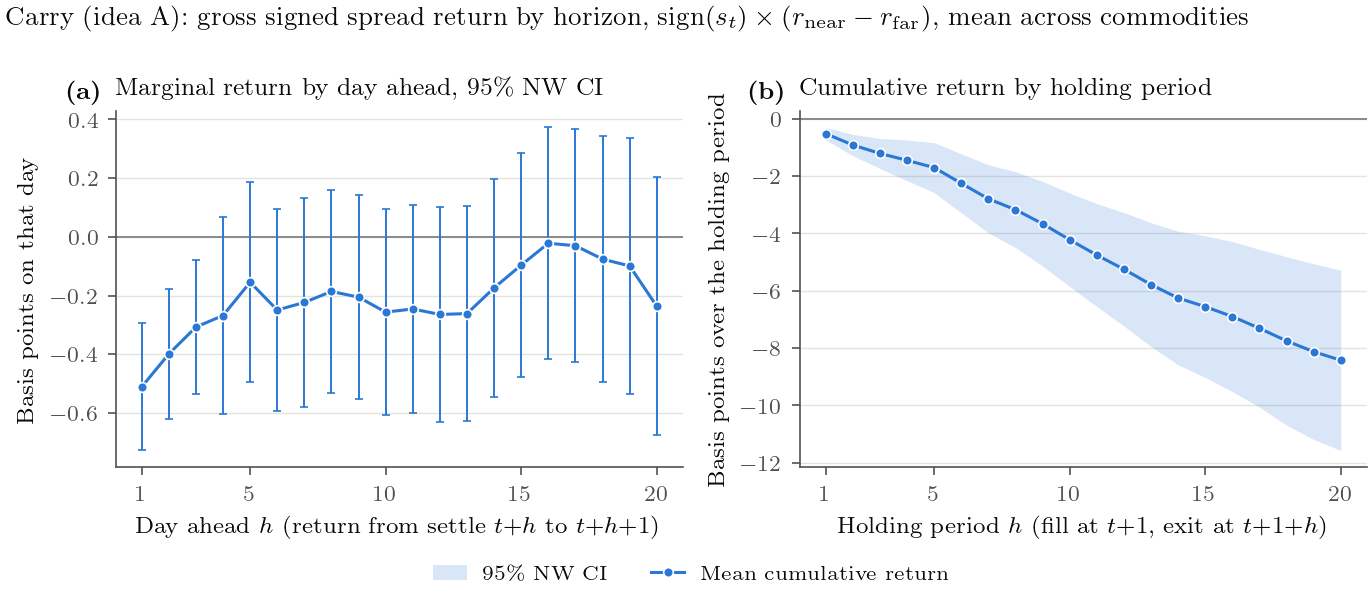

In [13]:
fig = F.horizon_decay(marg, cum, STRATEGY)
ps.save(fig, "carry_horizon_decay");

### 时序 IC 和自身历史分组

**所有策略都是时序的**：每个商品只和自己的历史比，不在商品之间排序（各交易所 settlement 时刻不同，截面也只有 ~20 个品种）。

- 时序 IC：每个商品自己的时间序列上，年化 carry 和 `[t+1, t+6]` spread return 的 Spearman 相关；`ALL` 是跨商品等权平均。
- 分组：每个商品按**截至 t 的历史分位数**（expanding，ex ante）把 carry 分成 5 组，再跨商品平均。Q1 = 相对自身历史最 contango。

In [14]:
ic_table = horizon.ts_ic(fwd, sig, col="fwd_1_6", score_col="carry_ann")
ic_roll = horizon.rolling_ts_ic(fwd, sig, col="fwd_1_6", score_col="carry_ann", window=252)
bins = horizon.bin_returns(fwd, sig, col="fwd_1_6", score_col="carry_ann", n_bins=5)
display(ic_table.round(3))
display(bins.round(2))

,root,ic,t_nw,n
0,BO,-0.079,-4.408,10271
1,C,-0.001,-0.032,10270
2,CC,-0.076,-3.992,10222
3,CL,-0.009,-0.418,10244
4,CO,-0.030,-1.583,9763
5,CT,-0.090,-4.700,10248
6,FC,-0.061,-3.238,9827
7,GC,-0.024,-1.401,10246
8,HG,-0.133,-6.581,9507
9,HO,-0.094,-4.579,10119


,bin,mean_bps,t_nw,n
0,1,4.77,3.85,42476
1,2,1.78,2.41,44277
2,3,1.22,1.80,45784
3,4,1.49,1.66,49879
4,5,-2.69,-1.73,47857


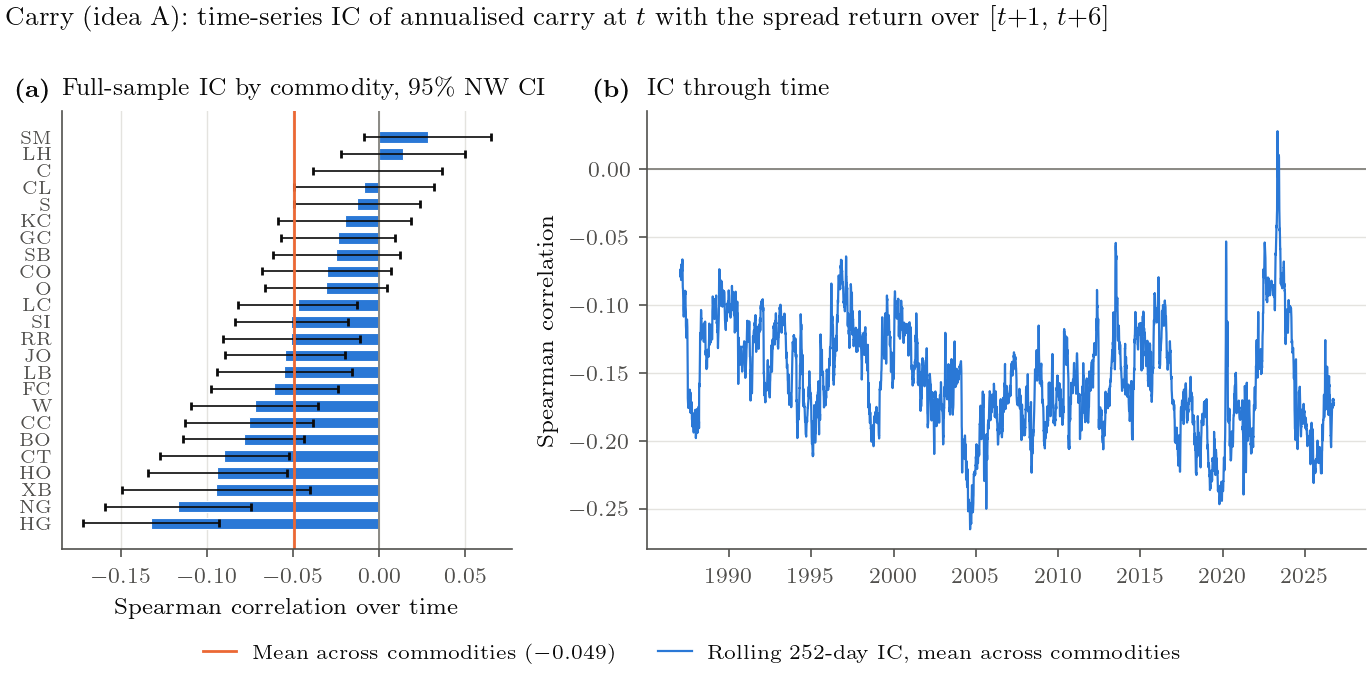

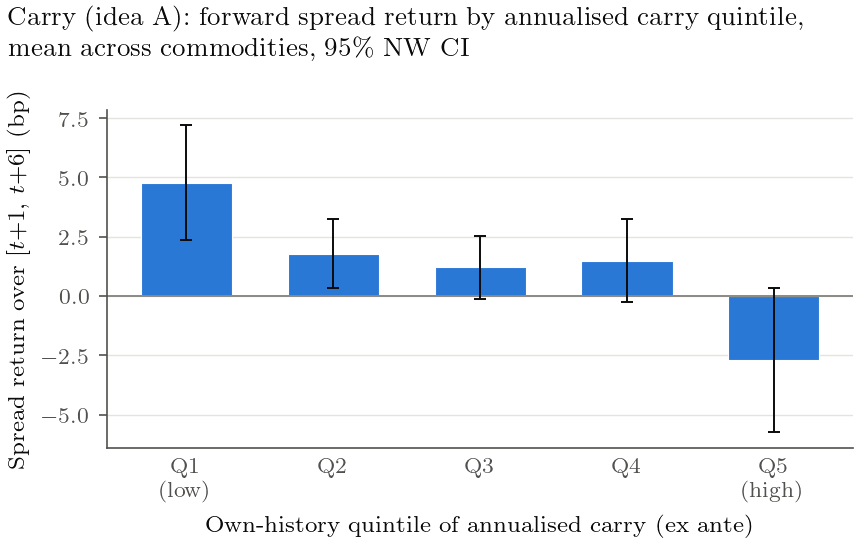

In [15]:
window = r"$[t{+}1,\,t{+}6]$"
fig = F.time_series_ic(ic_table, ic_roll, STRATEGY, "annualised carry", window)
ps.save(fig, "carry_time_series_ic")
fig = F.quintile_returns(bins, STRATEGY, "annualised carry", window)
ps.save(fig, "carry_quintile_returns");

### 每个商品的 IC 显著吗：block bootstrap

上面 IC 的 t 值依赖 NW 近似。这里直接看分布：每个商品在自己的日期序列上做 moving-block bootstrap（块长 21 天，保留 5 天重叠窗口和 carry 持续性带来的序列相关），重抽 2000 次，每次算时序 Spearman IC。

图里每个商品一条竖着的 histogram，黑点和竖线是估计值和 95% 区间，上方印双侧 p 值（2 × min(P(IC* ≤ 0), P(IC* ≥ 0))）。p < 0.05 用蓝色。

In [16]:
boot, boot_draws = horizon.block_bootstrap_ic(fwd, sig, col="fwd_1_6", score_col="carry_ann",
                                              block=21, n_boot=2000, seed=0)
print(f"p < 0.05: {(boot['p_value'] < 0.05).sum()} of {len(boot)} commodities")
display(boot.sort_values("ic").round(3))

p < 0.05: 14 of 24 commodities


,root,ic,ci_lo,ci_hi,p_value,n
8,HG,-0.133,-0.175,-0.093,0.000,9507
15,NG,-0.117,-0.161,-0.072,0.000,9174
23,XB,-0.095,-0.152,-0.030,0.004,5290
9,HO,-0.094,-0.140,-0.049,0.000,10119
5,CT,-0.090,-0.132,-0.050,0.000,10248
0,BO,-0.079,-0.117,-0.040,0.000,10271
2,CC,-0.076,-0.115,-0.033,0.000,10222
22,W,-0.072,-0.113,-0.032,0.000,10270
6,FC,-0.061,-0.096,-0.021,0.003,9827
12,LB,-0.055,-0.097,-0.013,0.007,9224


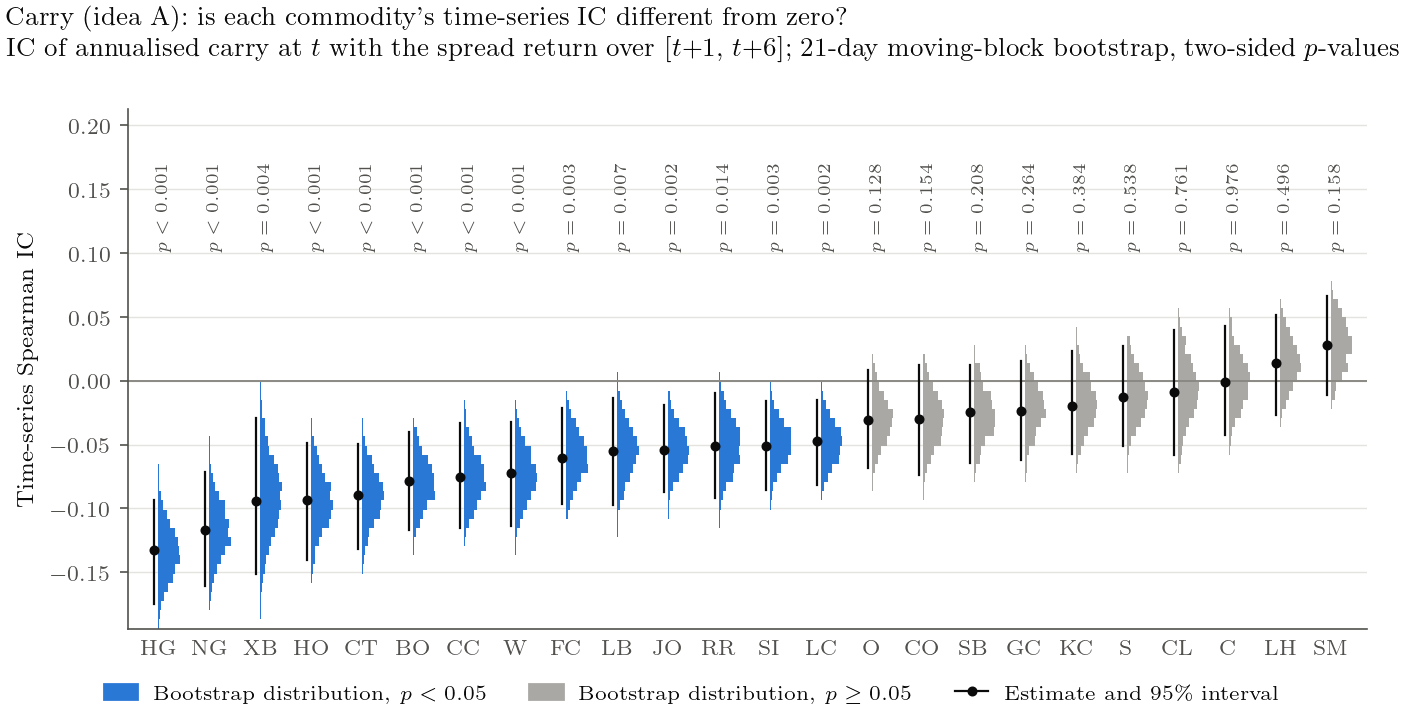

In [17]:
fig = F.bootstrap_ic_distribution(boot, boot_draws, STRATEGY, "annualised carry", window, block=21)
ps.save(fig, "carry_bootstrap_ic");

## 6. k 天分批调仓（每天调 1/k）

仓位 = 过去 k 天 target 的平均（Jegadeesh–Titman overlapping portfolios）。k 越大，信号翻向引起的换手越少，但 roll 的换手省不掉。
k 取 1…60 共 12 个点；图 (b) 里 gross 和 net-of-all 带 95% NW CI。

In [18]:
ks = report.k_sweep(sig, pairs, mk, ks=[1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 60], config=cfg)
display(ks[["k", "turnover_x", "ret_gross", "t_gross", "ret_- fees", "ret_- impact (all)"]].round(3))

,k,turnover_x,ret_gross,t_gross,ret_- fees,ret_- impact (all)
0,1,26.148,-0.484,-3.456,-1.002,-2.612
1,2,23.587,-0.433,-3.231,-0.896,-2.126
2,3,22.196,-0.370,-2.836,-0.803,-1.874
3,4,21.448,-0.342,-2.635,-0.760,-1.765
4,5,20.760,-0.319,-2.480,-0.723,-1.673
5,7,19.814,-0.274,-2.142,-0.658,-1.539
6,10,18.936,-0.246,-1.929,-0.612,-1.446
7,15,17.887,-0.205,-1.639,-0.551,-1.341
8,20,17.241,-0.176,-1.418,-0.510,-1.278
9,30,16.256,-0.128,-1.060,-0.445,-1.177


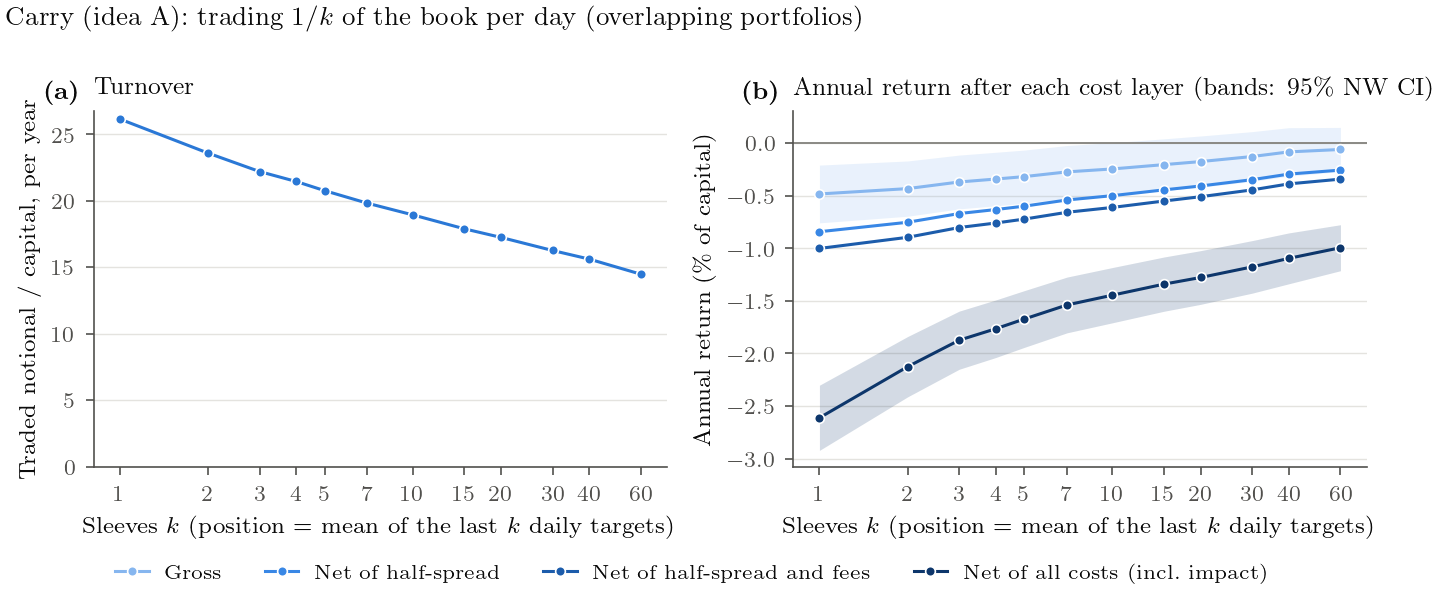

In [19]:
fig = F.k_sweep(ks, STRATEGY)
ps.save(fig, "carry_k_sweep");

## 7. 策略规模：成本怎么随资本变化

持仓和每笔交易量都和资本成正比（允许小数张），所以不用重跑回测：把每笔交易按 C/C₀ 放大后重新算成本即可（`tests/test_simulate.py` 里验证过和完整重跑一致）。

half-spread 和 fee 占资本的比例**不随规模变**；impact 超过第一张之后约按 √capital 增长。表从 \$1m 到 \$1bn。

In [20]:
cap = report.capacity_curve(res, capitals=[1e6, 3e6, 1e7, 3e7, 1e8, 3e8, 1e9])
display(cap.round(3))

,capital,gross_bps_yr,half_spread_bps_yr,fee_bps_yr,impact_bps_yr,ann_ret_pct,sharpe
0,1.000000e+06,-48.411,35.893,15.943,26.449,-1.267,-1.314
1,3.000000e+06,-48.411,35.893,15.943,74.762,-1.750,-1.795
2,1.000000e+07,-48.411,35.893,15.943,160.925,-2.612,-2.596
3,3.000000e+07,-48.411,35.893,15.943,291.328,-3.916,-3.620
4,1.000000e+08,-48.411,35.893,15.943,539.961,-6.402,-4.924
5,3.000000e+08,-48.411,35.893,15.943,939.238,-10.395,-5.880
6,1.000000e+09,-48.411,35.893,15.943,1717.360,-18.176,-6.409


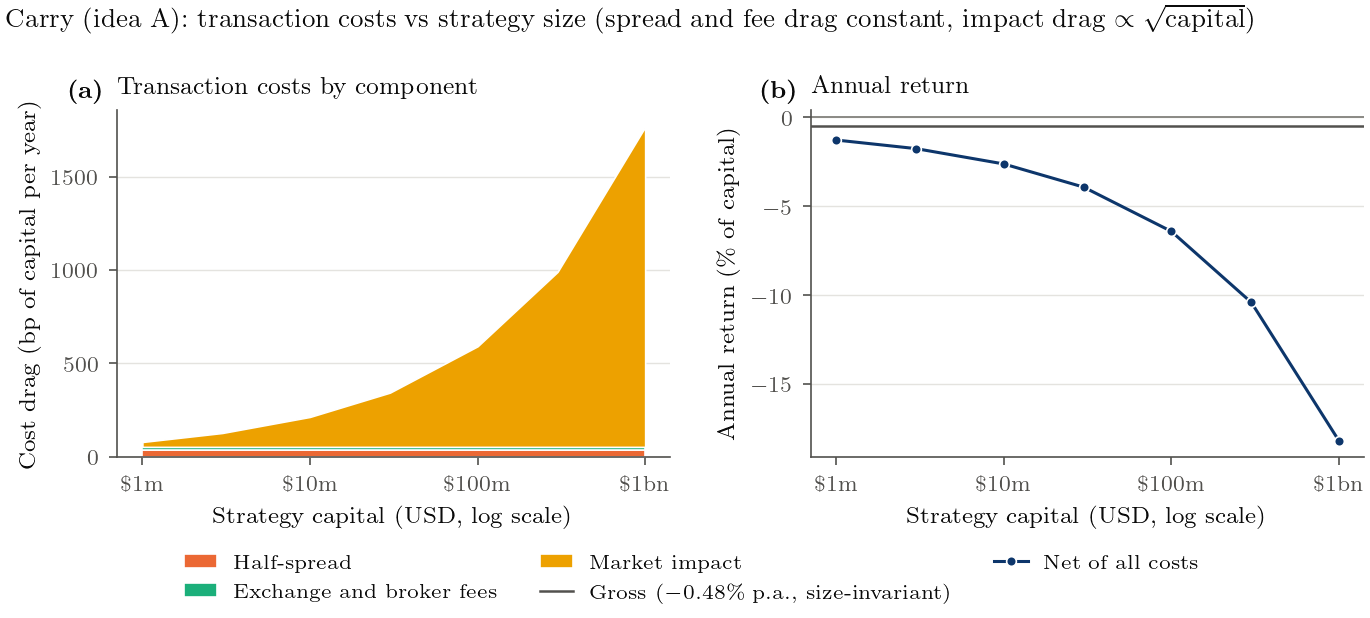

In [21]:
fig = F.capacity(cap, STRATEGY)
ps.save(fig, "carry_capacity");

## 8. 仓位分配：等权 vs 流动性加权

等权时每个商品都拿 ~1/N 的资本（\$10m 下约 \$45 万 gross）：同样的仓位在 CL、GC 里只占日成交量的 0.01%，在燕麦、橙汁里却占几个百分点，**最薄的市场决定了容量**。

替代方案 `scheme="liquidity"`：权重 ∝ (dollar ADV)^α（较薄那条腿，滞后）。α = 0 是等权，α = 1 让各商品 participation 相同，这里用 α = 0.5。默认仍是等权（论文口径）。
下面先比较两种分配的分层绩效和每个商品的 impact，再比较两条规模曲线。

In [22]:
legs_liq = sizing.legs_from_signal(sig, pairs, scheme="liquidity", alpha=0.5, leg_ratio="notional")
res_liq = simulate.simulate(legs_liq, mk, cfg)

perf_sizing = pd.concat({
    "equal": report.performance_table(res),
    "liquidity a=0.5": report.performance_table(res_liq),
}, names=["sizing"])
display(perf_sizing)

book = pd.concat({
    "equal": report.root_table(res)[["impact_bps_of_book", "median_participation"]],
    "liquidity a=0.5": report.root_table(res_liq)[["impact_bps_of_book", "median_participation"]],
}, axis=1)
display(book.sort_values(("equal", "impact_bps_of_book")).round(4))

layer  ann_ret_pct  ann_vol_pct  sharpe    t_nw  max_dd_pct  turnover_x  cost_bps_yr
sizing                                                                                                          
equal           0           gross       -0.484        0.957  -0.506  -3.456     -24.239      26.148        0.000
                1   - half-spread       -0.843        0.958  -0.880  -5.988     -38.224      26.148       35.893
                2          - fees       -1.002        0.959  -1.045  -7.098     -44.462      26.148       51.836
                3  - impact (all)       -2.612        1.006  -2.596 -16.528    -109.099      26.148      212.761
liquidity a=0.5 0           gross       -0.343        1.194  -0.288  -1.907     -20.542      28.563        0.000
                1   - half-spread       -0.618        1.194  -0.518  -3.426     -29.385      28.563       27.477
                2          - fees       -0.765        1.194  -0.641  -4.234     -34.577      28.563       42.174
                3  - impact (all)       -1.618        1.204  -1.344  -8.642     -68.961      28.563      127.511

equal                         liquidity a=0.5                     
     impact_bps_of_book median_participation impact_bps_of_book median_participation
root                                                                                
XB              17.1560               0.0001            19.6531               0.0001
GC              34.8258               0.0004            11.5183               0.0001
LC              41.8596               0.0011            61.3335               0.0006
C               51.5612               0.0003            38.1120               0.0002
CT              56.7304               0.0014            43.4157               0.0005
HG              58.3297               0.0007            36.0597               0.0002
KC              59.6076               0.0007            47.7320               0.0003
SI              63.2533               0.0011            46.0119               0.0002
CO              76.4161               0.0002            73.6735               0.0002
W               76.9451               0.0006            49.3245               0.0003
S               81.8052               0.0004            68.5576               0.0003
LH             106.5513               0.0021            79.9975               0.0008
BO             112.0843               0.0018            98.3475               0.0006
FC             112.8768               0.0053            57.8406               0.0013
SM             116.7882               0.0015           109.8375               0.0007
CL             123.0775               0.0001           156.4733               0.0002
HO             135.8929               0.0004           144.3138               0.0003
SB             149.2389               0.0016            68.3680               0.0005
NG             172.7322               0.0003           127.5314               0.0003
RR             234.2502               0.0422            77.2663               0.0018
LB             240.0477               0.0245            69.1013               0.0028
CC             297.8412               0.0018            82.5611               0.0006
JO             431.8195               0.0215           161.5220               0.0017
O              557.4641               0.0631           150.8254               0.0037

capital  gross_bps_yr  half_spread_bps_yr  fee_bps_yr  impact_bps_yr  ann_ret_pct  sharpe
sizing                                                                                                                                              
Equal weight, $1/N$ per commodity                  0  1.000000e+06       -48.411              35.893      15.943         26.449       -1.267  -1.314
                                                   1  3.000000e+06       -48.411              35.893      15.943         74.762       -1.750  -1.795
                                                   2  1.000000e+07       -48.411              35.893      15.943        160.925       -2.612  -2.596
                                                   3  3.000000e+07       -48.411              35.893      15.943        291.328       -3.916  -3.620
                                                   4  1.000000e+08       -48.411              35.893      15.943        539.961       -6.402  -4.924
                                                   5  3.000000e+08       -48.411              35.893      15.943        939.238      -10.395  -5.880
                                                   6  1.000000e+09       -48.411              35.893      15.943       1717.360      -18.176  -6.409
Liquidity weight, $\propto(\text{dollar ADV})^{... 0  1.000000e+06       -34.334              27.477      14.697         14.733       -0.912  -0.764
                                                   1  3.000000e+06       -34.334              27.477      14.697         38.874       -1.154  -0.964
                                                   2  1.000000e+07       -34.334              27.477      14.697         85.338       -1.618  -1.344
                                                   3  3.000000e+07       -34.334              27.477      14.697        156.854       -2.334  -1.906
                                                   4  1.000000e+08       -34.334              27.477      14.697        292.705       -3.692  -2.857
                                                   5  3.000000e+08       -34.334              27.477      14.697        510.183       -5.867  -3.997
                                                   6  1.000000e+09       -34.334              27.477      14.697        933.514      -10.100  -5.152

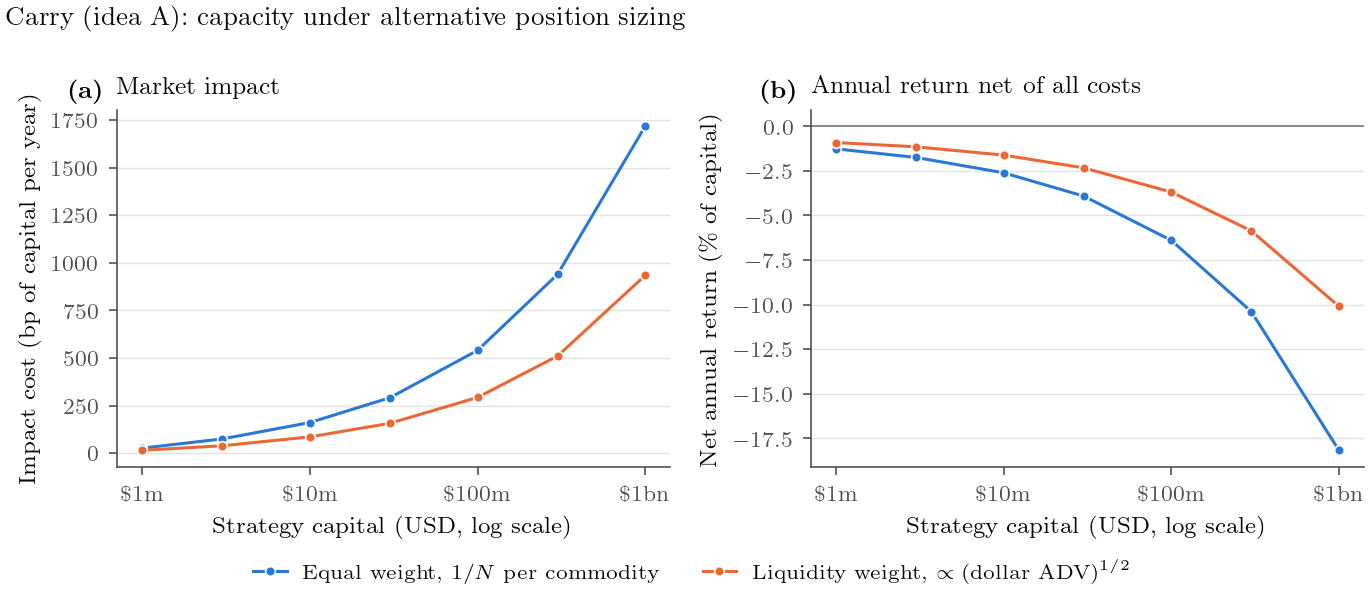

In [23]:
capitals = [1e6, 3e6, 1e7, 3e7, 1e8, 3e8, 1e9]
cap_cmp = {
    r"Equal weight, $1/N$ per commodity": report.capacity_curve(res, capitals),
    r"Liquidity weight, $\propto(\text{dollar ADV})^{1/2}$": report.capacity_curve(res_liq, capitals),
}
display(pd.concat(cap_cmp, names=["sizing"]).round(3))
fig = F.capacity_compare(cap_cmp, STRATEGY)
ps.save(fig, "carry_capacity_by_sizing");

## 9. 读这个结果

**框架层面**：同一个 signal 现在能同时回答四个问题——gross 有没有 edge、edge 在哪个 horizon、成本吃掉多少、能放多大。

**A（carry）本身仍然是负结果**，和 `02_carry` 一致：

- \$10m 下 gross −0.48%/年；扣 half-spread −0.84%，再扣 fee −1.00%，再扣 impact −2.61%；换手 ~26×/年。Test 期 gross −0.27%，不显著。
- **Horizon**：逐日边际 signed return 只有前 3 天显著（t+1 −0.51 bp，t_NW −4.6；t+3 −0.31 bp，−2.6），第 4 天以后不显著、在 −0.1 到 −0.25 bp 附近徘徊；
  累计收益持续变负，20 天约 −8.4 bp。**信息集中在信号后头几天**，backwardation 做多的方向是错的。
- **时序 IC**：平均 −0.049，24 个商品里 22 个为负；21 天 block bootstrap 下 14 个 p < 0.05，其中 13 个 p < 0.01，和 NW 结论一致。
  Q1（相对自身历史最 contango）后 5 天 +4.8 bp，Q5 −2.7 bp：一个商品的 carry 比它平时高的时候，spread 之后反而偏弱——这是**时序**上的反向信息。
- **k**：k 从 1 到 60，换手 26× → 15×；分批调仓省的是翻向的成本，roll 的成本省不掉。
- **规模**只影响 impact：\$1m 时 26 bp/年（小于 half-spread 36 bp），\$10m 时 161 bp，\$1bn 时 1,717 bp。
- 流动性加权（α = 0.5）把 \$10m 的 impact 从 161 降到 85 bp/年，net 从 −2.61% 到 −1.62%；燕麦的 participation 从 6.3% 降到 0.4%。

**注意**：允许小数张合约，小资本时忽略了整数取整；impact 用的是单腿 outright 的波动率和成交量，按 listed spread 下单时实际会更小，所以 impact 这一层偏保守。
square-root law 描述的是大单（metaorder），所以每笔订单的第一张不收 impact。

## 10. 下一步

- D（curve momentum）、E（Nelson–Siegel）：只写 signal function（输出 `date, root, target`，可选 `score`），其余全部复用。
- C 已在 main 上作为 mixed/negative 收尾（D-010–D-012）；如需日频 CL/NG 复现，v2 和 `rebalance="daily"`（D-015）已经支持。
- A 的时序反向信息（前 3 天、14/24 显著）可以作为一个独立 signal 检验，但要先定好规则再看 test 期。
- Robustness：`min_adv` 阈值、impact 用 spread 波动率而不是单腿波动率、`execution="legs"`、fee 敏感性、bootstrap 块长。
- 报告里保留负结果，不要用 test 期调参。